# Unit 9 code companion: Models with a Distribution and Predictors

In Unit 8, every quote had the same booking probability and every job had the same expected number of boxes. Here we let those depend on predictors. We will fit a logistic regression to the moving company's quotes, turn its probabilities into crew decisions, and judge those decisions on held-out quotes. Then we will return to the box counts from Unit 8 and fit a Poisson regression.

Run the cells in order. Each section follows the slides. Try changing an input, such as the threshold or the costs, and compare the new results with the original ones.

## Setup

Import the packages and load the 1,500 quotes. Each row is one quote, and `booked` is 1 if the customer went on to book the move.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, log_loss)

quotes = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/moving_quotes.csv")
quotes.head()

,booked,days_ahead,source,volume_cuft,discount_pct,weekend
0,0,6,referral,766,0,1
1,0,13,phone,660,10,1
2,0,36,web,366,5,0
3,0,22,web,1047,0,0
4,0,8,referral,860,0,0


## 1. Booking rates by how the request came in

Start with the raw booking rates. These are the numbers in the first table of the slides.

In [2]:
print(len(quotes), "quotes,", quotes.booked.sum(), "booked")
quotes.groupby("source").booked.agg(["size", "mean"]).round(3)

1500 quotes, 295 booked


,size,mean
source,,
phone,464,0.220
referral,295,0.339
web,741,0.126


Referrals book at almost three times the rate of web requests. A model with predictors lets us estimate a booking probability for each quote, rather than one shared $p$.

## 2. Why not fit a straight line?

Fit least squares to the 0/1 booking indicator and count the quotes that get a negative predicted probability.

In [3]:
line = smf.ols("booked ~ days_ahead", data=quotes).fit()
a, b = line.params
print(f"line: {a:.3f} + ({b:.4f}) x days")
print(f"the line reaches zero at {-a / b:.1f} days")
print("quotes with a negative prediction:", (line.fittedvalues < 0).sum())

line: 0.307 + (-0.0056) x days
the line reaches zero at 55.2 days
quotes with a negative prediction: 29


A probability can't be negative, but the line goes below zero for requests made far ahead. A logistic curve stays between 0 and 1.

## 3. Probability, odds, and log odds

Convert a few probabilities to odds and log odds. Try adding 0.99 to the list.

In [4]:
p = np.array([0.10, 0.20, 0.50, 0.80, 0.90])
pd.DataFrame({"p": p, "odds": p / (1 - p), "log odds": np.log(p / (1 - p))}).round(3)

,p,odds,log odds
0,0.1,0.111,-2.197
1,0.2,0.250,-1.386
2,0.5,1.000,0.000
3,0.8,4.000,1.386
4,0.9,9.000,2.197


Odds run from 0 to infinity, and log odds run over all real numbers. That's why a linear predictor goes on the log odds scale.

## 4. Booking and lead time

Fit a logistic regression with one predictor. `smf.logit` works like `smf.ols`, with a 0/1 outcome.

In [5]:
one = smf.logit("booked ~ days_ahead", data=quotes).fit(disp=0)
b0, b1 = one.params
print(f"log odds = {b0:.3f} + ({b1:.4f}) x days ahead")

days = pd.DataFrame({"days_ahead": [3, 14, 30, 60]})
days["predicted p"] = one.predict(days).round(3)
days

log odds = -0.587 + (-0.0471) x days ahead


,days_ahead,predicted p
0,3,0.326
1,14,0.223
2,30,0.119
3,60,0.032


`predict` returns probabilities, not log odds. By hand, the probability is $1/(1+e^{-(b_0+b_1x)})$. Check one value from the table that way.

In [6]:
x = 14
print(1 / (1 + np.exp(-(b0 + b1 * x))))

0.22340804865275804


## 5. Reading the slope three ways

The slope is a change in log odds. Exponentiate it to get an odds ratio, and multiply by $p(1-p)$ for the approximate change in probability.

In [7]:
print("odds ratio per day :", round(np.exp(b1), 4))
print("odds ratio per week:", round(np.exp(7 * b1), 3))
print("approx. change in p per day near p = 0.20:", round(0.2 * 0.8 * b1, 4))
print("largest possible change per day, b/4    :", round(b1 / 4, 4))

odds ratio per day : 0.954
odds ratio per week: 0.719
approx. change in p per day near p = 0.20: -0.0075
largest possible change per day, b/4    : -0.0118


The odds ratio is the same at every starting point. The change in probability is not: it is largest near $p=0.5$ and small when $p$ is close to 0 or 1. Try computing the change near $p=0.05$.

## 6. The coefficients come from likelihood

Software chooses the coefficients with the largest log-likelihood. Compute the log-likelihood yourself from the fitted probabilities and compare it with what `statsmodels` reports.

In [8]:
p_i = one.predict(quotes)
y = quotes.booked
by_hand = np.sum(y * np.log(p_i) + (1 - y) * np.log(1 - p_i))
print("log-likelihood, by hand   :", round(by_hand, 2))
print("log-likelihood, statsmodels:", round(one.llf, 2))
print("with no predictors        :", round(one.llnull, 2))

log-likelihood, by hand   : -710.46
log-likelihood, statsmodels: -710.46
with no predictors        : -743.62


Each booking contributes $\log p_i$ and each non-booking contributes $\log(1-p_i)$, as in Unit 8's binomial likelihood. The difference is that each quote now has its own $p_i$.

## 7. A model with several predictors

Fit the full model and put the odds ratios beside their confidence intervals. `C(source, Treatment('web'))` makes web requests the baseline.

In [9]:
full = smf.logit("booked ~ C(source, Treatment('web')) + days_ahead + volume_cuft"
                 " + discount_pct + weekend", data=quotes).fit(disp=0)
table = pd.DataFrame({"coef": full.params, "SE": full.bse,
                      "odds ratio": np.exp(full.params)})
table[["OR lower", "OR upper"]] = np.exp(full.conf_int())
table.round(4)

,coef,SE,odds ratio,OR lower,OR upper
Intercept,-1.3777,0.2963,0.2522,0.1411,0.4507
"C(source, Treatment('web'))[T.phone]",0.7030,0.1658,2.0199,1.4594,2.7956
"C(source, Treatment('web'))[T.referral]",1.4014,0.1778,4.0607,2.8656,5.7541
days_ahead,-0.0522,0.0069,0.9491,0.9364,0.9620
volume_cuft,-0.0009,0.0003,0.9991,0.9985,0.9997
discount_pct,0.1121,0.0134,1.1186,1.0897,1.1483
weekend,-0.0114,0.1515,0.9887,0.7347,1.3305


Per cubic foot, the volume odds ratio is so close to 1 that it is hard to read. Rescale it, and put the lead time and discount in more useful units too.

In [10]:
c = full.params
print("per week ahead          :", round(np.exp(7 * c["days_ahead"]), 3))
print("per 5 points of discount:", round(np.exp(5 * c["discount_pct"]), 3))
print("per 100 cubic feet      :", round(np.exp(100 * c["volume_cuft"]), 3))

per week ahead          : 0.694
per 5 points of discount: 1.751
per 100 cubic feet      : 0.914


The discount was assigned at random, so its odds ratio can be read as an effect of offering a discount. Lead time was chosen by customers, so its odds ratio is an association. The weekend interval includes 1.

## 8. Comparing two booking rates

Compare referrals with web requests, first with Unit 1's two-proportion test and then with a logistic regression on one indicator.

In [11]:
two = quotes[quotes.source.isin(["web", "referral"])].copy()
two["referral"] = (two.source == "referral").astype(int)
p_r = two[two.referral == 1].booked.mean()
p_w = two[two.referral == 0].booked.mean()
n_r, n_w = (two.referral == 1).sum(), (two.referral == 0).sum()
pool = two.booked.mean()
z_test = (p_r - p_w) / np.sqrt(pool * (1 - pool) * (1 / n_r + 1 / n_w))

m = smf.logit("booked ~ referral", data=two).fit(disp=0)
print(f"rates: referral {p_r:.3f}, web {p_w:.3f}")
print(f"odds ratio from the rates: {(p_r / (1 - p_r)) / (p_w / (1 - p_w)):.3f}")
print(f"odds ratio from the model: {np.exp(m.params['referral']):.3f}")
print(f"two-proportion z = {z_test:.2f}, logistic z = {m.tvalues['referral']:.2f}")

rates: referral 0.339, web 0.126
odds ratio from the rates: 3.573
odds ratio from the model: 3.573
two-proportion z = 7.96, logistic z = 7.69


With one indicator and no other predictors, the model's odds ratio matches the one computed from the two rates. The $z$ statistics differ a little because the two methods estimate the standard error differently.

## 9. A predicted probability for one quote

A phone request for a weekday move, 14 days out, 800 cubic feet. Fitting the same model with `smf.glm` gives confidence intervals for the predicted probability.

In [12]:
glm = smf.glm("booked ~ C(source, Treatment('web')) + days_ahead + volume_cuft"
              " + discount_pct + weekend", data=quotes,
              family=sm.families.Binomial()).fit()
quote = pd.DataFrame({"source": ["phone"] * 3, "days_ahead": [14] * 3,
                      "volume_cuft": [800] * 3, "discount_pct": [0, 10, 15],
                      "weekend": [0] * 3})
pred = glm.get_prediction(quote).summary_frame(alpha=0.05)
pred.index = ["no discount", "10%", "15%"]
pred[["mean", "mean_ci_lower", "mean_ci_upper"]].round(3)

,mean,mean_ci_lower,mean_ci_upper
no discount,0.107,0.077,0.146
10%,0.268,0.220,0.322
15%,0.391,0.322,0.464


`smf.glm` with the binomial family fits the same model as `smf.logit`. Its coefficients match the table in section 7.

## 10. Held-out quotes and the confusion matrix

Fit to 70% of the quotes and judge on the other 30%, with the same split as Unit 6. At a threshold of 0.5, count the four kinds of outcome.

In [13]:
train, test = train_test_split(quotes, test_size=0.3, random_state=0)
fit = smf.logit("booked ~ C(source, Treatment('web')) + days_ahead + volume_cuft"
                " + discount_pct + weekend", data=train).fit(disp=0)
p_test = fit.predict(test)
y_test = test.booked

flag = (p_test >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, flag).ravel()
print(f"TP {tp}  FP {fp}  FN {fn}  TN {tn}")
print("accuracy             :", round((tp + tn) / len(y_test), 3))
print("predict no one books :", round(1 - y_test.mean(), 3))

TP 12  FP 15  FN 72  TN 351
accuracy             : 0.807
predict no one books : 0.813


`confusion_matrix` puts the actual outcome in rows and the prediction in columns, with 0 first. `.ravel()` reads them out in the order TN, FP, FN, TP. At 0.5, the model is slightly less accurate than predicting that no one books.

## 11. Precision, recall, and F1

Compute the three by hand from the counts, then check them with `sklearn`.

In [14]:
print("precision:", round(tp / (tp + fp), 3), round(precision_score(y_test, flag), 3))
print("recall   :", round(tp / (tp + fn), 3), round(recall_score(y_test, flag), 3))
print("F1       :", round(2 * tp / (2 * tp + fp + fn), 3), round(f1_score(y_test, flag), 3))
print("specificity:", round(tn / (tn + fp), 3))

precision: 0.444 0.444
recall   : 0.143 0.143
F1       : 0.216 0.216
specificity: 0.959


## 12. Choosing a threshold from costs

An idle crew costs \$150 and a booking with no crew ready costs \$450. Compute each rule's cost per quote, along with its accuracy, recall, and F1. Change the costs and see where the best threshold moves.

In [15]:
cost_fp, cost_fn = 150, 450
print("threshold from costs:", cost_fp / (cost_fp + cost_fn))

rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    flag_t = (p_test >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, flag_t).ravel()
    rows.append({"threshold": t, "flagged": tp_ + fp_,
                 "accuracy": (tp_ + tn_) / len(y_test),
                 "recall": tp_ / (tp_ + fn_),
                 "F1": f1_score(y_test, flag_t),
                 "cost per quote": (cost_fp * fp_ + cost_fn * fn_) / len(y_test)})
pd.DataFrame(rows).round(3)

threshold from costs: 0.25


,threshold,flagged,accuracy,recall,F1,cost per quote
0,0.10,303,0.469,0.881,0.382,86.333
1,0.15,232,0.582,0.762,0.405,76.000
2,0.20,181,0.660,0.667,0.423,69.667
3,0.25,144,0.693,0.536,0.395,72.000
4,0.30,105,0.740,0.429,0.381,71.000
5,0.40,55,0.807,0.310,0.374,67.667
6,0.50,27,0.807,0.143,0.216,77.000


The cost rule gives 0.25 if the probabilities are right. On these 450 quotes, 0.40 happens to cost a little less. Section 14 shows that the model's highest probabilities run a little high, and with only 84 bookings the cost at nearby thresholds moves around by chance. If you choose a threshold by scanning the test set, its cost there will look better than it would on new quotes.

## 13. The ROC curve and AUC

Plot the true positive rate against the false positive rate across every threshold.

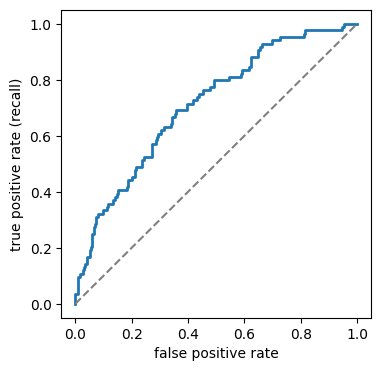

AUC: 0.713


In [16]:
fpr, tpr, _ = roc_curve(y_test, p_test)
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(fpr, tpr, lw=2)
ax.plot([0, 1], [0, 1], ls="--", color="grey")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate (recall)")
plt.show()
print("AUC:", round(roc_auc_score(y_test, p_test), 3))

AUC is the share of (booked, not booked) pairs where the booked quote gets the higher probability. The next cell checks that by comparing every pair directly.

In [17]:
yes = p_test[y_test == 1].to_numpy()
no = p_test[y_test == 0].to_numpy()
diff = yes[:, None] - no[None, :]
print("share of pairs ranked correctly:", round(((diff > 0) + 0.5 * (diff == 0)).mean(), 3))
print("AUC after squaring every p     :", round(roc_auc_score(y_test, p_test**2), 3))

share of pairs ranked correctly: 0.713
AUC after squaring every p     : 0.713


Squaring every probability keeps the same ranking, so AUC is unchanged, but the probabilities themselves are now much too low. AUC can't tell you whether the probabilities are right.

## 14. Calibration and expected bookings

Sort the held-out quotes into five groups by predicted probability and compare the average prediction with the share that booked.

In [18]:
groups = pd.qcut(p_test, 5)
pd.DataFrame({"predicted": p_test, "booked": y_test}).groupby(groups, observed=True).agg(
    average_predicted=("predicted", "mean"), share_booked=("booked", "mean"),
    quotes=("booked", "size")).round(3)

,average_predicted,share_booked,quotes
"(0.00021999999999999993, 0.0579]",0.031,0.044,90
"(0.0579, 0.117]",0.090,0.133,90
"(0.117, 0.202]",0.157,0.144,90
"(0.202, 0.314]",0.258,0.233,90
"(0.314, 0.794]",0.456,0.378,90


In [19]:
expected = p_test.sum()
sd = np.sqrt((p_test * (1 - p_test)).sum())
print(f"expected bookings {expected:.1f} (SD {sd:.1f}); actually booked {y_test.sum()}")

expected bookings 89.4 (SD 7.8); actually booked 84


Each quote is a yes-or-no variable with mean $\hat p_i$, so the expected total is the sum of the probabilities. Try the same sum with the squared probabilities from section 13.

## 15. Comparing models on held-out quotes

Log loss is the negative average log-likelihood on the held-out quotes. Lower is better.

In [20]:
formulas = {
    "days ahead only": "booked ~ days_ahead",
    "all but the discount": "booked ~ C(source, Treatment('web')) + days_ahead"
                            " + volume_cuft + weekend",
    "all predictors": "booked ~ C(source, Treatment('web')) + days_ahead"
                      " + volume_cuft + discount_pct + weekend",
}
base = np.full(len(y_test), train.booked.mean())
print(f"{'training rate for everyone':28s} AUC 0.500  log loss {log_loss(y_test, base):.3f}")
for name, f in formulas.items():
    p = smf.logit(f, data=train).fit(disp=0).predict(test)
    print(f"{name:28s} AUC {roc_auc_score(y_test, p):.3f}  log loss {log_loss(y_test, p):.3f}")

training rate for everyone   AUC 0.500  log loss 0.482
days ahead only              AUC 0.591  log loss 0.478
all but the discount         AUC 0.664  log loss 0.458
all predictors               AUC 0.713  log loss 0.439


## 16. Poisson regression for box counts

Now return to Unit 8's moving jobs. A single Poisson mean left the box counts with a variance almost seven times the mean. Let the expected count depend on volume.

In [21]:
jobs = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/moving_jobs.csv")
pois = sm.families.Poisson()


def dispersion(model):
    return model.pearson_chi2 / model.df_resid


none = smf.glm("est_boxes ~ 1", data=jobs, family=pois).fit()
vol = smf.glm("est_boxes ~ volume_cuft", data=jobs, family=pois).fit()
print("dispersion, one mean    :", round(dispersion(none), 2))
print("dispersion, with volume :", round(dispersion(vol), 2))
print("multiplier per 100 cu ft:", round(np.exp(100 * vol.params["volume_cuft"]), 3))

dispersion, one mean    : 6.76
dispersion, with volume : 1.49
multiplier per 100 cu ft: 1.154


The dispersion ratio compares the leftover variation with what a Poisson expects at each fitted mean. A ratio near 1 is what a Poisson model predicts.

## 17. Exposure and offsets

Check whether boxes are proportional to volume by using log volume as a predictor. A coefficient of 1 means twice the volume gives twice the boxes.

In [22]:
logv = smf.glm("est_boxes ~ np.log(volume_cuft)", data=jobs, family=pois).fit()
print("coefficient on log volume:", round(logv.params.iloc[1], 3))
print("95% CI:", logv.conf_int().iloc[1].round(3).tolist())

off = smf.glm("est_boxes ~ 1", data=jobs, family=pois,
              offset=np.log(jobs.volume_cuft)).fit()
print("boxes per 100 cubic feet :", round(100 * np.exp(off.params.iloc[0]), 2))
print("dispersion, offset model :", round(dispersion(off), 2))
print("AIC: volume", round(vol.aic), " offset", round(off.aic))

coefficient on log volume: 0.993
95% CI: [0.959, 1.028]
boxes per 100 cubic feet : 8.39
dispersion, offset model : 1.27
AIC: volume 4480  offset 4275


The offset fixes the log-volume coefficient at 1, so the model estimates one rate per cubic foot. Volume is the exposure.

## 18. Allowing for remaining overdispersion

`scale="X2"` gives quasi-Poisson standard errors: the same coefficients, with each standard error multiplied by the square root of the dispersion ratio.

In [23]:
quasi = smf.glm("est_boxes ~ volume_cuft", data=jobs, family=pois).fit(scale="X2")
print(f"Poisson SE      : {vol.bse['volume_cuft']:.6f}")
print(f"quasi-Poisson SE: {quasi.bse['volume_cuft']:.6f}")
print("ratio           :", round(quasi.bse["volume_cuft"] / vol.bse["volume_cuft"], 3),
      " sqrt(dispersion):", round(np.sqrt(dispersion(vol)), 3))

Poisson SE      : 0.000024
quasi-Poisson SE: 0.000030
ratio           : 1.219  sqrt(dispersion): 1.219


## 19. One family of models

Linear, logistic, and Poisson regression are all generalized linear models. Fit an ordinary regression as a GLM with the normal (Gaussian) family and compare it with `smf.ols`.

In [24]:
ols = smf.ols("hours ~ volume_cuft", data=jobs).fit()
gauss = smf.glm("hours ~ volume_cuft", data=jobs, family=sm.families.Gaussian()).fit()
print(ols.params.round(5).to_dict())
print(gauss.params.round(5).to_dict())

{'Intercept': 1.6695, 'volume_cuft': 0.01246}
{'Intercept': 1.6695, 'volume_cuft': 0.01246}


The coefficients match. For normal errors with constant variance, maximum likelihood gives the least squares fit. Changing the family and link gives logistic or Poisson regression.